# Knowing What You Do Not Know: the code, in one notebook

This notebook goes with our paper *Knowing What You Do Not Know: Open-World Follow-Up Planning for Fading Transients, from One Spacecraft to a Fleet*, submitted to the Journal of Astrophysics and Astronomy and now under review.

It does three things. First it pulls the repository and the committed result files. Then it rebuilds every headline number and figure in the paper from those files, so you can check that nothing was typed by hand. Last, it runs a small simulation of its own, so you can watch the planner with and without the "none of the above" option.

It runs on a free Colab CPU in a few minutes. Nothing here needs a GPU.

In [1]:
import os, subprocess, sys
REPO = "orbitalnet-dashboard"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/joycemalik/orbitalnet-dashboard.git", REPO], check=True)
os.chdir(REPO)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "numpy==2.2.6", "scipy==1.16.0", "sgp4==2.25", "matplotlib==3.10.5"], check=True)
print("ready")

ready


## 1. The idea in one picture

A planner that only knows $K$ classes has a posterior that always sums to one. So when something new comes in, every extra measurement pushes it towards whichever known class fits least badly. It gets *more* sure exactly when it should get less sure.

We add one more hypothesis, $h_0$, "none of the above". The toy below shows the difference. Each measurement fits the known classes badly, and the closed-world posterior still collapses onto one of them, while the open-world one moves its mass to $h_0$.

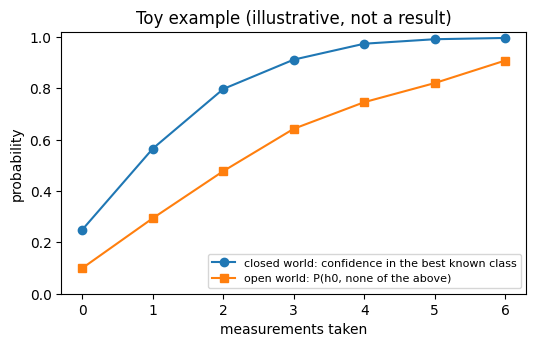

In [2]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(0)
K = 4
# likelihood of each new measurement under the 4 known classes (all poor fits, one a bit less poor)
like_known = np.array([0.20, 0.08, 0.06, 0.05])
like_h0 = 0.35                       # a broad nonparametric model fits the odd event better
closed = np.full(K, 1 / K); open_ = np.r_[np.full(K, 0.9 / K), 0.1]
hist_c, hist_o = [closed.max()], [open_[-1]]
for _ in range(6):
    l = like_known * rng.uniform(0.8, 1.2, K)
    closed = closed * l; closed /= closed.sum()
    open_ = open_ * np.r_[l, like_h0]; open_ /= open_.sum()
    hist_c.append(closed.max()); hist_o.append(open_[-1])
plt.figure(figsize=(6, 3.4))
plt.plot(hist_c, "o-", label="closed world: confidence in the best known class")
plt.plot(hist_o, "s-", label="open world: P(h0, none of the above)")
plt.xlabel("measurements taken"); plt.ylabel("probability"); plt.ylim(0, 1.02)
plt.title("Toy example (illustrative, not a result)"); plt.legend(fontsize=8); plt.show()

## 2. Rebuild the paper's numbers from the result files

`research/figures/paper_main.py` and `phase4_numbers.py` read only `research/results/` and write the LaTeX macros the paper uses. We run them and print the headline values.

In [3]:
subprocess.run([sys.executable, "-m", "research.figures.paper_main"], check=True)
subprocess.run([sys.executable, "-m", "research.figures.phase4_numbers"], check=True)
import re, glob
nums = {}
for f in glob.glob("research/papers/main/generated/numbers*.tex"):
    for k, v in re.findall(r"newcommand\{.(\w+)\}\{(.*)\}", open(f, encoding="utf-8").read()):
        nums[k] = v
show = {
  "Simulation: unknowns caught at 5% false alarms, open world (P)": "SimTprP",
  "Simulation: same, closed-world EIG (B3)": "SimTprBthree",
  "Real ZTF events replayed": "RealNEvents",
  "Real: confidently wrong on unknowns, P": "RealCCwWhP",
  "Real: confidently wrong on unknowns, B3": "RealCCwWhBthree",
  "Fleet: one plane vs spread, accuracy gap (points)": "FleetBFourMag",
}
for label, key in show.items():
    print(f"{label:62s} {nums.get(key, '?').replace(chr(92) + '%', '%').replace('--', '–')}")

Simulation: unknowns caught at 5% false alarms, open world (P) 96%
Simulation: same, closed-world EIG (B3)                        21%
Real ZTF events replayed                                       364
Real: confidently wrong on unknowns, P                         7–14%
Real: confidently wrong on unknowns, B3                        50–56%
Fleet: one plane vs spread, accuracy gap (points)              9.4


## 3. The ROC curve, from the raw analysis file

How well does each method's "this is new" score separate never-seen event types from known ones? The dotted line is the 5% false-alarm point we fixed before running the test seeds.

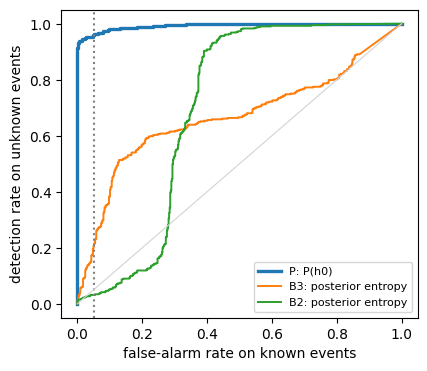

TPR at 5% FPR  P: 0.961  B3: 0.206


In [4]:
import json
a = json.load(open("research/results/phase2/analysis_test.json"))
s1 = {r["scenario"]: r for r in a["runs"]}["S1_nominal"]
roc = s1["H3"]["roc"]
plt.figure(figsize=(4.6, 4))
for k, lab in [("P_p_h0", "P: P(h0)"), ("B3_entropy", "B3: posterior entropy"), ("B2_entropy", "B2: posterior entropy")]:
    plt.plot(roc[k]["fpr"], roc[k]["tpr"], label=lab, lw=2.4 if k == "P_p_h0" else 1.4)
plt.axvline(0.05, ls=":", c="grey"); plt.plot([0, 1], [0, 1], c="lightgrey", lw=0.8)
plt.xlabel("false-alarm rate on known events"); plt.ylabel("detection rate on unknown events")
plt.legend(fontsize=8); plt.show()
print("TPR at 5% FPR  P:", round(s1["H3"]["P_tpr_at_fpr"], 3), " B3:", round(s1["H3"]["comparators"]["B3_entropy"]["tpr_at_fpr"], 3))

## 4. Run a small simulation yourself

This is the Phase 1 existence proof, at a small size. It writes to a scratch folder, so the committed results are untouched. Change the seed and see how much the picture moves. With only a few events the numbers are noisy, which is exactly why the paper uses 1000 events and sealed test seeds.

In [5]:
SEED, N_EVENTS = 7, 40
out = "/tmp/orbitalnet_demo"
subprocess.run([sys.executable, "-m", "research.experiments.phase1_existence_proof", "--seed", str(SEED),
                "--n-events", str(N_EVENTS), "--out-dir", out, "--tag", "demo",
                "--progress-file", out + "/progress.json"], check=True)
summary = json.load(open(glob.glob(out + "/**/summary.json", recursive=True)[0]))
summary.pop("config", None)
print(json.dumps({k: v for k, v in summary.items() if k not in ("config_hash", "git_commit")}, indent=1)[:2500])

{
 "generated_at": "2026-11-24T16:19:31.771327+00:00",
 "strategies": {
  "random": {
   "n_events": 40,
   "confident_wrong_rate_overall": 0.3,
   "confident_wrong_rate_modeled": 0.03571428571428571,
   "confident_wrong_rate_withheld": 0.9166666666666666,
   "accuracy_modeled": 0.9285714285714286,
   "accuracy_withheld": 0.0,
   "mean_max_posterior": 0.976731961766275,
   "mean_confident_rate": 0.95
  },
  "B3_closed_world_eig": {
   "n_events": 40,
   "confident_wrong_rate_overall": 0.3,
   "confident_wrong_rate_modeled": 0.0,
   "confident_wrong_rate_withheld": 1.0,
   "accuracy_modeled": 1.0,
   "accuracy_withheld": 0.0,
   "mean_max_posterior": 0.9819879713194751,
   "mean_confident_rate": 0.95
  },
  "P_open_world_eig": {
   "n_events": 40,
   "confident_wrong_rate_overall": 0.05,
   "confident_wrong_rate_modeled": 0.0,
   "confident_wrong_rate_withheld": 0.16666666666666666,
   "accuracy_modeled": 1.0,
   "accuracy_withheld": 0.75,
   "mean_max_posterior": 0.9691172312681926,
  

## 5. What to take away

Adding $h_0$ is cheap. It costs almost nothing on known events, and it stops the planner from becoming confidently wrong about new ones. Every prediction in the paper was written down before the test data were run, and the ones that failed are reported too.

The paper, the website and this notebook all read from the same result files. If a number here ever disagrees with the paper, the files are right and we want to hear about it.